In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import os
import re

import skbio # Mantel test

In [2]:
os.getcwd()

'/Users/connor/Documents/github/sperm-data-analysis/notebooks'

In [3]:
# change working directory to root project folder 
os.chdir('../experiments/full_pipeline')

In [4]:
#1. FILTER TOGGLES

# Example usage:
# sample_filter = None     # Include ALL samples (default)
# sample_filter = 1        # Only sample 1
# sample_filter = [1, 3]   # Only sample 1 and 3
sample_filter = None   # <<< SET THIS

# Example usage:
# fish_filter = None               # All fish
# fish_filter = "fish1"            # Only fish1
# fish_filter = ["fish1", "fish2"] # Only selected fish
fish_filter = None    # <<< SET THIS

none_barcode = "NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE_NONE"
# none_barcode = 'yellow'
fish_filter = ['fish1',    'fish10',    'fish12',    'fish13',    'fish14',    'fish15',
    'fish16',    'fish17',    'fish18',     'fish2',    'fish22',    'fish26',
    'fish35',    'fish37',    'fish38',     'fish4',    'fish40',    'fish42',
    'fish44',    'fish45',     'fish5',    'fish50',    'fish51',     'fish8']

In [5]:
#2. Load data (adjust file path and method depending on your file format)
df_working = pd.read_csv("final_data.csv") 
# or if Excel:
# df = pd.read_excel("your_file.xlsx")

In [6]:
df_working['fish'].unique()

<StringArray>
[    'fish1',    'fish10',    'fish12',    'fish13',    'fish14',    'fish15',
    'fish16',    'fish17',    'fish18',     'fish2',    'fish22',    'fish26',
    'fish35',    'fish37',    'fish38',     'fish4',    'fish40',    'fish42',
    'fish44',    'fish45',     'fish5',    'fish50',    'fish51',     'fish8',
 'fishctrl1', 'fishctrl2', 'fishctrl3']
Length: 27, dtype: str

In [7]:
df_working['sample'].unique()

array([ 1,  2,  5,  6,  7,  8, 10, 11, 12, 13, 14,  4,  9, 15, 16, 18, 17])

In [8]:
#3. APPLY SAMPLE FILTER
if sample_filter is not None:
    if isinstance(sample_filter, int):
        sample_filter = [sample_filter]
    df_working = df_working[df_working["sample"].isin(sample_filter)]

print("Samples included:", df_working["sample"].unique())

Samples included: [ 1  2  5  6  7  8 10 11 12 13 14  4  9 15 16 18 17]


In [9]:
#4. APPLY FISH FILTER
if fish_filter is not None:
    if isinstance(fish_filter, str):
        fish_filter = [fish_filter]
    df_working = df_working[df_working["fish"].isin(fish_filter)]

print("Fish included:", df_working["fish"].unique())

Fish included: <StringArray>
[ 'fish1', 'fish10', 'fish12', 'fish13', 'fish14', 'fish15', 'fish16',
 'fish17', 'fish18',  'fish2', 'fish22', 'fish26', 'fish35', 'fish37',
 'fish38',  'fish4', 'fish40', 'fish42', 'fish44', 'fish45',  'fish5',
 'fish50', 'fish51',  'fish8']
Length: 24, dtype: str


In [10]:
#5. REMOVE "NONE" BARCODE AND FISHWATER SAMPLES
df_working = df_working[df_working["barcode"] != none_barcode]
df_working = df_working[~df_working["fish"].str.contains("fishwater", case=False)]

In [11]:
#6. COLLAPSE REPLICATES → per-fish barcode count table
fish_barcode_counts = (
    df_working
    .groupby(["fish", "barcode"])["reads"]
    .sum()
    .unstack(fill_value=0)
)

# Reorder fish numerically
fish_barcode_counts = fish_barcode_counts.reindex(
    sorted(fish_barcode_counts.index, key=lambda x: int(x.replace("fish", "")))
)

fish_list = fish_barcode_counts.index.tolist()
n_fish = len(fish_list)

In [12]:
#6b. ORDER FISH NUMERICALLY
def extract_fish_number(name):
    match = re.search(r'(\d+)', name)
    return int(match.group(1)) if match else float("inf")

fish_all = list(fish_barcode_counts.index)

fish_regular = sorted(
    [f for f in fish_all if "fishctrl" not in f.lower()],
    key=extract_fish_number
)

fish_ctrl = sorted(
    [f for f in fish_all if "fishctrl" in f.lower()],
    key=extract_fish_number
)

fish_order = fish_regular + fish_ctrl

fish_barcode_counts = fish_barcode_counts.reindex(fish_order)

fish_list = fish_barcode_counts.index.tolist()
n_fish = len(fish_list)

In [13]:
#7. CALCULATE COSINE SIMILARITY
cos_sim_matrix = cosine_similarity(fish_barcode_counts)
cos_sim_df = pd.DataFrame(cos_sim_matrix, index=fish_list, columns=fish_list)

In [14]:
#8. COMPUTE SHARED BARCODE COUNTS
shared_counts = np.dot(
    (fish_barcode_counts > 0).astype(int),
    (fish_barcode_counts > 0).astype(int).T
)
shared_df = pd.DataFrame(shared_counts, index=fish_list, columns=fish_list)

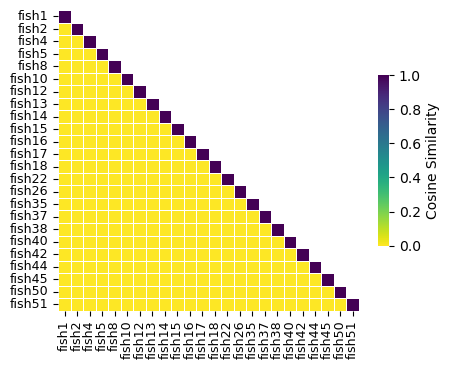

In [15]:
# 9. PLOT FISH-TO-FISH COSINE SIMILARITY
mask = np.triu(np.ones_like(cos_sim_df, dtype=bool), k=1)  # hide upper triangle

#Dynamically set figure size and font size
n_fish = len(fish_order)
fig_size = max(3.5, n_fish * 0.20)  # Slightly larger for more spacing
annot_font_size = max(4, 8 - (n_fish * 0.05))  # Smaller annotations
label_font_size = max(6, 11 - (n_fish * 0.08))

plt.figure(figsize=(fig_size, fig_size))
ax = sns.heatmap(
    cos_sim_df,
    mask=mask,
    cmap='viridis_r',
    fmt='d',
    annot_kws={"size": annot_font_size, "ha": "center", "va": "center"},
    cbar_kws={
        'label': 'Cosine Similarity',
        'shrink': 0.4,
        'aspect': 15
    },
    square=True,
    linewidths=0.5,
    xticklabels=True,  # Force all labels to show
    yticklabels=True   # Force all labels to show
)

# Set font sizes for axis labels and ticks
ax.tick_params(axis='both', labelsize=label_font_size)
plt.setp(ax.get_xticklabels(), fontsize=label_font_size, rotation=0)
plt.setp(ax.get_yticklabels(), fontsize=label_font_size, rotation=0)

# Center tick marks in the middle of boxes
ax.set_xticks([i + 0.5 for i in range(len(fish_order))])
ax.set_yticks([i + 0.5 for i in range(len(fish_order))])
ax.set_xticklabels(fish_order, fontsize=label_font_size, rotation=90)
ax.set_yticklabels(fish_order, fontsize=label_font_size, rotation=0)

# Remove axis labels (but keep tick labels)
ax.set_xlabel('')
ax.set_ylabel('')

plt.tight_layout(pad=1.5)  # Add more padding to prevent label cutoff
#plt.savefig("Fig1_Cosine_v2.svg", bbox_inches='tight', transparent=True)
#plt.savefig("Fig1_Cosine_v2.png", dpi=600, bbox_inches='tight', transparent=True)
plt.show()

In [16]:
#10. PLOT SAMPLE-TO-SAMPLE COSINE SIMILARITY (ONE FISH)

# Toggle: show shared barcode counts in off-diagonal boxes (True/False)
show_shared_sample_counts = False

# Toggle: show unique barcode counts on diagonal (True/False)
show_diagonal_counts = False

# Annotation text size inside cells (increase if you want bigger numbers)
annot_size = 6

# Sample mapping
sample_map = {
    1: 5, 
    2: 6, 
    3: 7, 
    4: 8, 
    5: 9, 
    6: 10, 
    7: 11, 
    8: 12, 
    9: 13, 
    10: 14, 
    11: 16, 
    12: 17, 
    13: 18, 
    14: 20, 
    15: 22, 
    16: 24, 
    17: 25, 
    18: 26
}

# Acceptable "one-fish selected" formats: string "fishX" or list ["fishX"]
one_fish_selected = False
if fish_filter is None:
    one_fish_selected = False
elif isinstance(fish_filter, str):
    one_fish_selected = True
    fish_name = fish_filter
elif isinstance(fish_filter, (list, tuple)) and len(fish_filter) == 1:
    one_fish_selected = True
    fish_name = fish_filter[0]
else:
    one_fish_selected = False

if not one_fish_selected:
    print("\n(Sample-to-sample plot not generated — select exactly one fish via fish_filter.)")
else:
    print(f"\nGenerating sample-to-sample cosine similarity plot for {fish_name}")

    # Subset df_working to the chosen fish (df_working comes from your pipeline)
    df_fish = df_working[df_working["fish"] == fish_name].copy()
    if df_fish.empty:
        print(f"No rows found for {fish_name} in df_working.")
    else:
        # Collapse replicates by averaging read_count across replicates for each sample
        sample_barcode_counts = (
            df_fish.groupby(["sample", "barcode"])["reads"]
            .mean()
            .unstack(fill_value=0)
        )

        # Remove NONE barcode if present
        if none_barcode in sample_barcode_counts.columns:
            sample_barcode_counts = sample_barcode_counts.drop(columns=[none_barcode])

        # Order samples by numeric sample number (robust to sample being int or string like "1","S1")
        def extract_sample_number(x):
            try:
                return int(x)
            except Exception:
                m = re.search(r'(\d+)', str(x))
                return int(m.group(1)) if m else float("inf")

        sample_index = sample_barcode_counts.index.tolist()
        sample_index_sorted = sorted(sample_index, key=extract_sample_number)
        sample_barcode_counts = sample_barcode_counts.reindex(sample_index_sorted)

        samples = sample_barcode_counts.index.tolist()
        n_samples = len(samples)

        # Compute cosine similarity between samples
        sample_cosine = cosine_similarity(sample_barcode_counts)
        sample_cosine_df = pd.DataFrame(sample_cosine, index=samples, columns=samples)

        # Compute shared barcode counts (presence/absence)
        presence = (sample_barcode_counts > 0).astype(int)
        shared_sample_counts = presence.dot(presence.T)
        shared_sample_df = pd.DataFrame(shared_sample_counts, index=samples, columns=samples)

        # Compute diagonal totals (unique barcodes per sample)
        diag_totals = presence.sum(axis=1)  # Series indexed by samples

        # Build annotation matrix:
        if show_shared_sample_counts:
            annot_df = shared_sample_df.copy().astype(int)
            # replace diagonal with totals or empty based on toggle
            for s in samples:
                if show_diagonal_counts:
                    annot_df.at[s, s] = int(diag_totals.loc[s])
                else:
                    annot_df.at[s, s] = ''
            annot_fmt = 's'  # Use string format to handle mixed int/empty
        else:
            annot_df = pd.DataFrame('', index=samples, columns=samples)
            # Only add diagonal counts if toggle is True
            if show_diagonal_counts:
                for s in samples:
                    annot_df.at[s, s] = f"{int(diag_totals.loc[s])}"
            annot_fmt = 's'

        # Mask upper triangle above diagonal, keep diagonal visible
        mask = np.triu(np.ones_like(sample_cosine_df, dtype=bool), k=1)

        # Create smaller figure
        fig, ax = plt.subplots(figsize=(3.25, 3.25))

        # Draw the heatmap WITHOUT automatic colorbar (we'll add it manually)
        sns.heatmap(
            sample_cosine_df,
            mask=mask,
            cmap="viridis_r",
            annot=annot_df,
            fmt=annot_fmt,
            annot_kws={"size": annot_size},
            square=True,
            cbar=False,  # Turn off automatic colorbar
            ax=ax,
            xticklabels=True,       # Show all x-axis tick labels
            yticklabels=True,       # Show all y-axis tick labels
        )

        # Apply sample mapping to axis labels
        current_xticklabels = [label.get_text() for label in ax.get_xticklabels()]
        current_yticklabels = [label.get_text() for label in ax.get_yticklabels()]
        
        # Map labels (convert to int, map, convert back to string)
        mapped_xticklabels = [str(sample_map.get(int(label), label)) for label in current_xticklabels]
        mapped_yticklabels = [str(sample_map.get(int(label), label)) for label in current_yticklabels]
        
        ax.set_xticklabels(mapped_xticklabels, fontsize=6)
        ax.set_yticklabels(mapped_yticklabels, fontsize=6, rotation=0)

        # Style heatmap ticks and title
        ax.tick_params(axis="both", labelsize=5)
        ax.set_title(
            f"{fish_name}",
            fontsize=7,
            pad=5
        )
        ax.set_xlabel("Age (months)", fontsize=5)
        ax.set_ylabel("Age (months)", fontsize=5)

        # Manually add horizontal colorbar in top right corner
        # Position: [left, bottom, width, height] in axes coordinates
        cax = fig.add_axes([0.65, 0.85, 0.3, 0.03])  # Adjust these values as needed
        
        # Create the colorbar
        import matplotlib.pyplot as plt
        from matplotlib.colorbar import ColorbarBase
        from matplotlib.colors import Normalize
        
        vmin = sample_cosine_df.values[~mask].min()
        vmax = sample_cosine_df.values[~mask].max()
        
        norm = Normalize(vmin=vmin, vmax=vmax)
        cbar = ColorbarBase(
            cax, 
            cmap=plt.cm.viridis_r,
            norm=norm,
            orientation='horizontal'
        )
        
        # Remove the black border (outline) around the colorbar
        cbar.outline.set_visible(False)
        
        # Customize colorbar with automatic tick spacing
        cbar.ax.tick_params(labelsize=5)
        cbar.set_label("Cosine similarity", fontsize=5, labelpad=3)
        
        # Calculate 4 evenly-spaced ticks: min, two intermediate values, max
        tick_positions = [vmin, 
                         vmin + (vmax - vmin) / 2, 
                         vmax]
        tick_labels = [f'{tick:.2f}' for tick in tick_positions]
        
        cbar.set_ticks(tick_positions)
        cbar.set_ticklabels(tick_labels)

        # plt.savefig(f'Supp_{fish_name}Cosine_v2.svg', bbox_inches='tight', transparent=True)
        # plt.savefig(f'Supp_{fish_name}Cosine_v2.png', dpi=600, bbox_inches='tight', transparent=True)
        plt.show()


(Sample-to-sample plot not generated — select exactly one fish via fish_filter.)



Generating sample-to-sample cosine similarity plots for 24 fish


/var/folders/59/35nb2tq50vz3vpwjkwkzppvh0000gn/T/ipykernel_10161/3741680135.py:251: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar on right


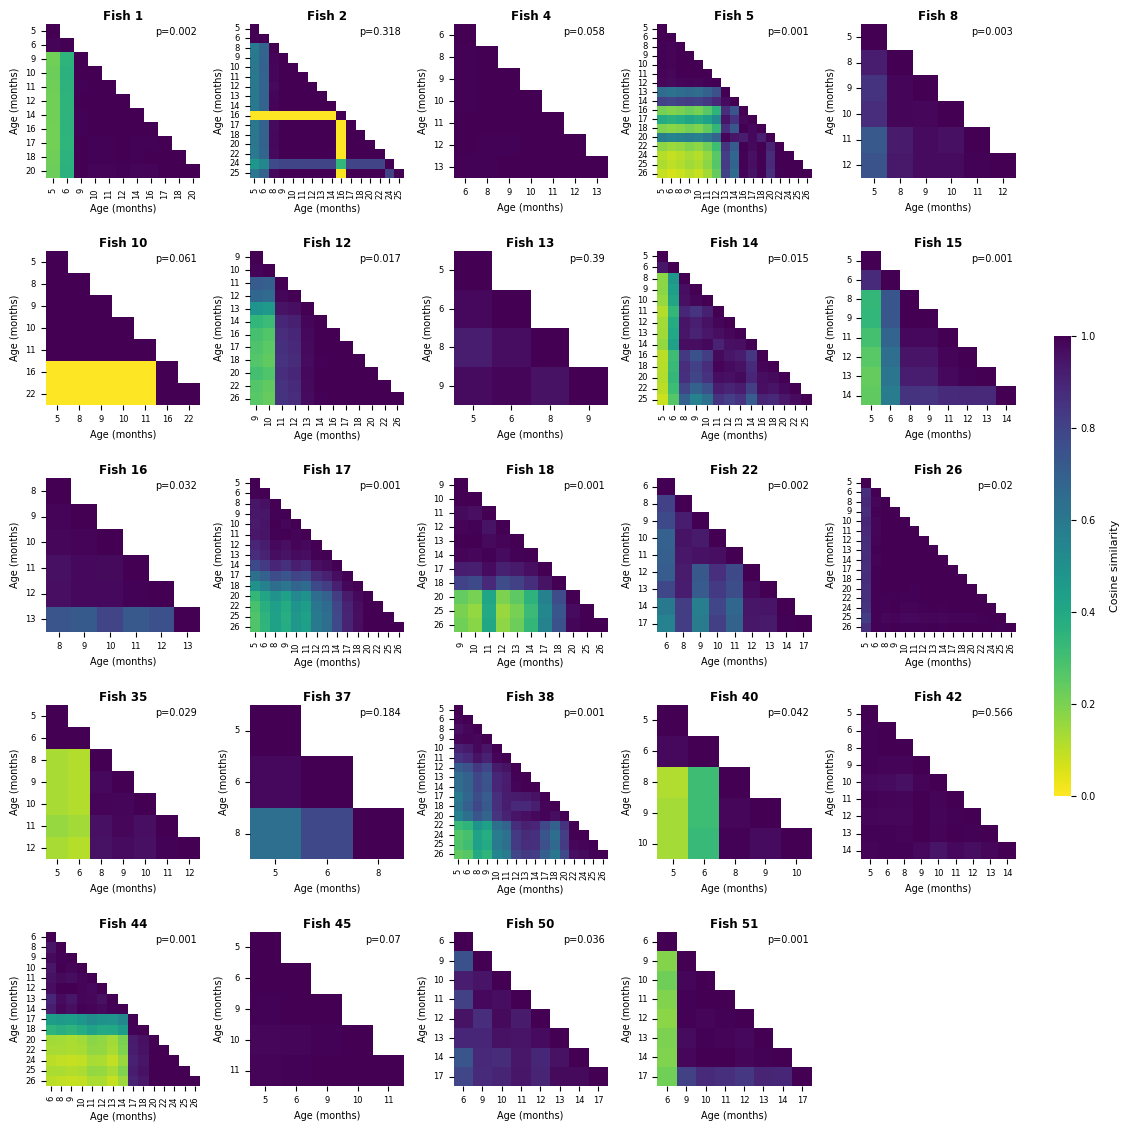

In [17]:
#11. PLOT SAMPLE-TO-SAMPLE COSINE SIMILARITY (MULTIPLE FISH FACETS)

# Toggle: show shared barcode counts in off-diagonal boxes (True/False)
show_shared_sample_counts = False

# Toggle: show unique barcode counts on diagonal (True/False)
show_diagonal_counts = False

# Annotation text size inside cells (increase if you want bigger numbers)
annot_size = 6

# List of fish to plot
fish_list = ["fish1", "fish2", "fish4", "fish5",
            "fish8", "fish10", "fish12", "fish13",
            "fish14", "fish15", "fish16", "fish17",
            "fish18", "fish22", "fish26", "fish35",
            "fish37", "fish38", "fish40", "fish42",
            "fish44", "fish45", "fish50", "fish51"
            ]

# Sample mapping
sample_map = {
    1: 5, 
    2: 6, 
    3: 7, 
    4: 8, 
    5: 9, 
    6: 10, 
    7: 11, 
    8: 12, 
    9: 13, 
    10: 14, 
    11: 16, 
    12: 17, 
    13: 18, 
    14: 20, 
    15: 22, 
    16: 24, 
    17: 25, 
    18: 26
}

if not fish_list or len(fish_list) == 0:
    print("\n(Multi-fish sample-to-sample plot not generated — provide a list of fish.)")
else:
    print(f"\nGenerating sample-to-sample cosine similarity plots for {len(fish_list)} fish")
    
    # Calculate grid dimensions (try to make it as square as possible)
    n_fish = len(fish_list)
    n_cols = 5
    #n_cols = int(np.ceil(np.sqrt(n_fish)))
    n_rows = 5
    #n_rows = int(np.ceil(n_fish / n_cols))
    
    # Create figure with subplots
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.3 * n_cols, 2.3 * n_rows))
    plt.subplots_adjust(hspace=0, wspace=0)  # No row spacing, small column spacing
    
    # Flatten axes array for easier iteration
    if n_fish == 1:
        axes = [axes]
    else:
        axes = axes.flatten() if n_rows > 1 or n_cols > 1 else [axes]
    
    # Store all similarity dataframes to find global min/max
    all_similarities = []
    fish_data = {}
    
    # Process each fish
    for fish_name in fish_list:
        # Subset df_working to the chosen fish
        df_fish = df_working[df_working["fish"] == fish_name].copy()
        
        if df_fish.empty:
            print(f"Warning: No rows found for {fish_name} in df_working.")
            continue
        
        # Collapse replicates by averaging read_count across replicates for each sample
        sample_barcode_counts = (
            df_fish.groupby(["sample", "barcode"])["reads"]
            .mean()
            .unstack(fill_value=0)
        )
        
        # Remove NONE barcode if present
        if none_barcode in sample_barcode_counts.columns:
            sample_barcode_counts = sample_barcode_counts.drop(columns=[none_barcode])
        
        # Order samples by numeric sample number
        def extract_sample_number(x):
            try:
                return int(x)
            except Exception:
                m = re.search(r'(\d+)', str(x))
                return int(m.group(1)) if m else float("inf")
        
        sample_index = sample_barcode_counts.index.tolist()
        sample_index_sorted = sorted(sample_index, key=extract_sample_number)
        sample_barcode_counts = sample_barcode_counts.reindex(sample_index_sorted)
        
        samples = sample_barcode_counts.index.tolist()
        
        # Compute cosine similarity between samples
        sample_cosine = cosine_similarity(sample_barcode_counts)
        sample_cosine_df = pd.DataFrame(sample_cosine, index=samples, columns=samples)
        
        # Compute shared barcode counts (presence/absence)
        presence = (sample_barcode_counts > 0).astype(int)
        shared_sample_counts = presence.dot(presence.T)
        shared_sample_df = pd.DataFrame(shared_sample_counts, index=samples, columns=samples)
        
        # Compute diagonal totals (unique barcodes per sample)
        diag_totals = presence.sum(axis=1)

        # Mantel test
        X = sample_cosine_df.to_numpy().copy()
        X[np.isclose(X, 1)] = 1
        
        times = np.array([sample_map[s] for s in samples])
        Y = np.abs(times[:, None] - times[None, :])
        
        coef, p, n = skbio.stats.distance.mantel(1 - X, Y, alternative = 'greater')
        
        # Store data for this fish
        mask = np.triu(np.ones_like(sample_cosine_df, dtype=bool), k=1)
        fish_data[fish_name] = {
            'sample_cosine_df': sample_cosine_df,
            'shared_sample_df': shared_sample_df,
            'diag_totals': diag_totals,
            'mask': mask,
            'samples': samples,
            'p': p,
        }
        
        # Collect similarity values for global scale
        all_similarities.extend(sample_cosine_df.values[~mask].tolist())
    
    # Calculate global min/max for consistent colorbar
    vmin_global = min(all_similarities)
    vmax_global = max(all_similarities)
    
    # Plot each fish
    for idx, fish_name in enumerate(fish_list):
        if fish_name not in fish_data:
            axes[idx].axis('off')
            continue
        
        ax = axes[idx]
        data = fish_data[fish_name]
        
        sample_cosine_df = data['sample_cosine_df']
        shared_sample_df = data['shared_sample_df']
        diag_totals = data['diag_totals']
        mask = data['mask']
        samples = data['samples']
        p = data['p']
        
        # Build annotation matrix
        if show_shared_sample_counts:
            annot_df = shared_sample_df.copy().astype(int)
            for s in samples:
                if show_diagonal_counts:
                    annot_df.at[s, s] = int(diag_totals.loc[s])
                else:
                    annot_df.at[s, s] = ''
            annot_fmt = 's'
        else:
            annot_df = pd.DataFrame('', index=samples, columns=samples)
            if show_diagonal_counts:
                for s in samples:
                    annot_df.at[s, s] = f"{int(diag_totals.loc[s])}"
            annot_fmt = 's'
        
        # Draw the heatmap
        sns.heatmap(
            sample_cosine_df,
            mask=mask,
            cmap="viridis_r",
            annot=annot_df,
            fmt=annot_fmt,
            annot_kws={"size": annot_size},
            square=True,
            cbar=False,
            ax=ax,
            xticklabels=True,
            yticklabels=True,
            vmin=vmin_global,
            vmax=vmax_global
        )
        
        # Apply sample mapping to axis labels
        current_xticklabels = [label.get_text() for label in ax.get_xticklabels()]
        current_yticklabels = [label.get_text() for label in ax.get_yticklabels()]
        
        mapped_xticklabels = [str(sample_map.get(int(label), label)) for label in current_xticklabels]
        mapped_yticklabels = [str(sample_map.get(int(label), label)) for label in current_yticklabels]
        
        ax.set_xticklabels(mapped_xticklabels, fontsize=7)
        ax.set_yticklabels(mapped_yticklabels, fontsize=7, rotation=0)
        
        # Style heatmap
        ax.tick_params(axis="both", labelsize=6)
        
        # Format title: "fish1" -> "Fish 1" (bold)
        # Extract number from fish name
        fish_number = ''.join(filter(str.isdigit, fish_name))
        formatted_title = f"Fish {fish_number}"
        ax.set_title(formatted_title, fontsize=8.5, pad=3, fontweight='bold')
        
        ax.set_xlabel("Age (months)", fontsize=7)
        ax.set_ylabel("Age (months)", fontsize=7)

        ax.text(0.98, 0.98, f'p={p:.3g}', transform = ax.transAxes, ha='right', va='top', fontsize=7)
    
    # Hide any unused subplots
    for idx in range(len(fish_list), len(axes)):
        axes[idx].axis('off')
    
    # Add single colorbar for all subplots (shorter version)
    # Position: [left, bottom, width, height] in figure coordinates
    cax = fig.add_axes([0.92, 0.3, 0.015, 0.4])  # Shorter colorbar (40% instead of 70%)
    
    from matplotlib.colorbar import ColorbarBase
    from matplotlib.colors import Normalize
    
    norm = Normalize(vmin=vmin_global, vmax=vmax_global)
    cbar = ColorbarBase(
        cax, 
        cmap=plt.cm.viridis_r,
        norm=norm,
        orientation='vertical'
    )
    
    # Remove the black border
    cbar.outline.set_visible(False)
    
    # Customize colorbar
    cbar.ax.tick_params(labelsize=7)
    cbar.set_label("Cosine similarity", fontsize=8, labelpad=10)
    
    # Set ticks every 0.2
    # Round min/max to nearest 0.2 boundaries
    tick_start = np.floor(vmin_global * 5) / 5  # Round down to nearest 0.2
    tick_end = min(1.0, np.ceil(vmax_global * 5) / 5)      # Round up to nearest 0.2
    tick_positions = np.arange(tick_start, tick_end + 0.01, 0.2)  # +0.01 to include endpoint
    tick_labels = [f'{tick:.1f}' for tick in tick_positions]
    
    cbar.set_ticks(tick_positions)
    cbar.set_ticklabels(tick_labels)
    
    plt.tight_layout(rect=[0, 0, 0.9, 1])  # Leave space for colorbar on right
    # plt.savefig(f'../../notebooks/Supp_AllFishCosine_v1.svg', bbox_inches='tight')
    # plt.savefig(f'../../notebooks/Supp_AllFishCosine_v1.png', dpi=600, bbox_inches='tight')
    plt.show()

In [18]:
d = fish_data[fish_list[3]]
X = d['sample_cosine_df'].to_numpy().copy()
X[np.isclose(X, 1)] = 1

times = np.array([sample_map[s] for s in d['samples']])
Y = np.abs(times[:, None] - times[None, :])

coef, p, n = skbio.stats.distance.mantel(1 - X, Y)
p

np.float64(0.001)

In [19]:
distance = []
similarity = []
i_s = []
j_s = []
fishes = []

for fish in fish_list:
    d = fish_data[fish]
    sample_cosine_df = d['sample_cosine_df']
    for i in sample_cosine_df.index:
        for j in sample_cosine_df.index:
            t1, t2 = sample_map[i], sample_map[j]
            if t1 == t2 or i > j: continue

            distance.append(np.abs(t1 - t2))
            similarity.append(sample_cosine_df.loc[i, j])
            i_s.append(t1)
            j_s.append(t2)
            fishes.append(fish)

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import ttest_ind, ks_2samp

cosine_df = pd.DataFrame({
    'similarity': similarity,
    'distance': distance,
    'i': i_s,
    'j': j_s,
    'fish': fishes,
})

cosine_df['is_adjacent'] = cosine_df['distance'] == 1
cosine_df['adjacent'] = cosine_df['is_adjacent'].map({True: '1 month apart', False: '$\\geq 2$ months apart'})
cosine_df['adjacent'] = pd.Categorical(cosine_df['adjacent'], categories=['1 month apart', '$\\geq 2$ months apart'], ordered = True)
cosine_df['fish'] = pd.Categorical(cosine_df['fish'])

cosine_df.head()

,similarity,distance,i,j,fish,is_adjacent,adjacent
0,0.989419,1,5,6,fish1,True,1 month apart
1,0.215024,4,5,9,fish1,False,$\geq 2$ months apart
2,0.223015,5,5,10,fish1,False,$\geq 2$ months apart
3,0.220580,6,5,11,fish1,False,$\geq 2$ months apart
4,0.215222,7,5,12,fish1,False,$\geq 2$ months apart


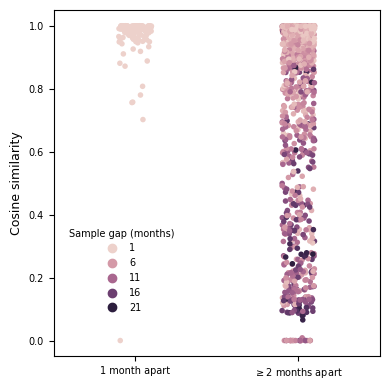

In [21]:
norm = plt.Normalize(cosine_df['distance'].min(), cosine_df['distance'].max())
cmap = sns.color_palette('cubehelix', as_cmap=True)

cmap = sns.cubehelix_palette(as_cmap=True)

plt.figure(figsize=(4, 4))

ax = sns.stripplot(
    data=cosine_df,
    x='adjacent',
    y='similarity',
    hue='distance',
    palette=cmap,
    size=4,
    dodge=False
)

# Axis labels
ax.set_xlabel('')
ax.set_ylabel('Cosine similarity', fontsize=9)

# Remove the automatic legend and manually add
# one with custom handles
ax.legend_.remove()
legend_distances = [1, 6, 11, 16, 21]

handles = [
    plt.Line2D([0], [0], marker='o', linestyle='',
        markersize=6, color=cmap(norm(d))
    ) for d in legend_distances
]

ax.legend(
    handles,
    [str(d) for d in legend_distances],
    title = 'Sample gap (months)',
    loc = 'lower left',
    bbox_to_anchor = (0.02, 0.1),
    frameon = False,
    fontsize = 7,
    title_fontsize = 7
)

ax.tick_params(axis="both", labelsize=7)

plt.tight_layout()

plt.savefig("../../notebooks/cosine-meta.svg", bbox_inches="tight")
plt.savefig("../../notebooks/cosine-meta.png", dpi=300, bbox_inches="tight")

plt.show()

In [28]:
cosine_df.query('is_adjacent and similarity < 0.4')

,similarity,distance,i,j,fish,is_adjacent,adjacent
154,0.0,1,16,17,fish2,True,1 month apart


In [29]:
model = smf.ols("similarity ~ distance", data=cosine_df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             similarity   R-squared:                       0.275
Model:                            OLS   Adj. R-squared:                  0.274
Method:                 Least Squares   F-statistic:                     472.9
Date:                Thu, 09 Apr 2026   Prob (F-statistic):           3.58e-89
Time:                        09:41:57   Log-Likelihood:                -93.400
No. Observations:                1251   AIC:                             190.8
Df Residuals:                    1249   BIC:                             201.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.9829      0.013     78.270      0.0

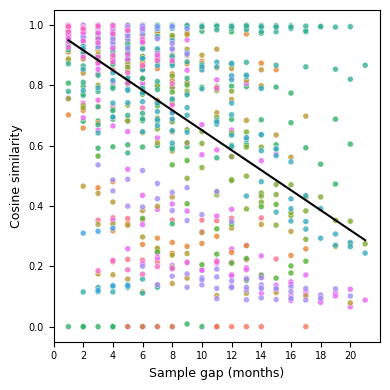

In [24]:
# Extract slope and intercept from the statsmodels OLS result
intercept = model.params["Intercept"]
slope = model.params["distance"]

# Build a smooth line across the observed distance range
x_vals = np.linspace(cosine_df["distance"].min(),
                     cosine_df["distance"].max(), 200)
y_vals = intercept + slope * x_vals

plt.figure(figsize=(4, 4))

ax = sns.scatterplot(
    data=cosine_df,
    x = 'distance',
    y = 'similarity',
    hue = 'fish',
    # palette = 'viridis',
    s = 18,
    alpha = 0.8,
    legend = False
)

# Best‑fit line
ax.plot(x_vals, y_vals, color="black", linewidth=1.5)

ax.set_xlabel('Sample gap (months)', fontsize=9)
ax.set_ylabel('Cosine similarity', fontsize=9)
ax.tick_params(axis = 'both', labelsize=7)

ax.set_xticks([0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20])

plt.tight_layout()
plt.show()

In [32]:
model = smf.mixedlm(
    "np.log(similarity) ~ distance",
    data=cosine_df,
    groups=cosine_df["fish"],
    re_formula="~distance"
).fit()

/opt/anaconda3/envs/weber/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/weber/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/envs/weber/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/opt/anaconda3/envs/weber/lib/python3.11/site-packages/numpy/linalg/_linalg.py:2325: RuntimeWarning: invalid value encountered in slogdet
  sign, logdet = _umath_linalg.slogdet(a, signature=signature)
/opt/anaconda3/envs/weber/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.war

In [38]:
np.log(cosine_df['similarity'])

/opt/anaconda3/envs/weber/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


0      -0.010638
1      -1.537005
2      -1.500517
3      -1.511496
4      -1.536083
          ...   
1246   -0.013506
1247   -0.171935
1248   -0.004224
1249   -0.105427
1250   -0.111712
Name: similarity, Length: 1251, dtype: float64

In [35]:
model.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
             Mixed Linear Model Regression Results
================================================================
Model:            MixedLM Dependent Variable: np.log(similarity)
No. Observations: 1251    Method:             REML              
No. Groups:       24      Scale:              nan               
Min. group size:  3       Log-Likelihood:     nan               
Max. group size:  136     Converged:          No                
Mean group size:  52.1                                          
-----------------------------------------------------------------
                        Coef.  Std.Err.  z  P>|z|  [0.025  0.975]
-----------------------------------------------------------------
Intercept                                                        
distance                                                         
Group Var                                                        
Group x distance Cov                                             
distance Var                                                     
================================================================

"""

In [30]:
# Kolmogorov-Smirnov test
adj = np.array(cosine_df[cosine_df['is_adjacent']]['similarity'])
nonadj = np.array(cosine_df[~cosine_df['is_adjacent']]['similarity'])

ks_stat, ks_p = ks_2samp(adj, nonadj)

print(f'KS test: statistic = {ks_stat:.4g}, p = {ks_p:.4g}')

KS test: statistic = 0.4899, p = 1.017e-28
